# Policy exercise 2: measuring residential segregation spatially

## 1. Question and connection to Notebook 1
Notebook 1 summarized the percentage of same-group neighbors, required relocation, and settling across repetitions. That percentage is informative: it measures very local association. However, one pooled percentage does not describe the full spatial arrangement or distinguish interwoven patterns from territorial separation.

**Question:** How does neighborhood segregation vary with the imposed minimum, and do those arrangements settle? Segregation concerns where groups live relative to each other. We therefore use locations and explicitly defined neighborhoods, rather than interpreting a percentage alone as a complete segregation measure.

The experiment retains 85% occupancy probability, a bounded 51 × 51 grid, minimums of 10–90% in five-point steps, 30 repetitions per setting, and the 1,000-cycle cap.

## 2. Outcomes: three established PySAL indices
We calculate all three on the **same local environments**: each focal patch and its up to eight surrounding patches. This includes the focal patch, unlike the model's neighbor-only relocation criterion. Neighborhoods overlap and shrink at the bounded edges.

- **Isolation (`Isolation`)** describes the same-group share of the local environments experienced by the focal group, with PySAL's population weighting. Higher values indicate greater isolation. Interpretation depends on the group's citywide proportion.
- **Correlation ratio (`CorrelationR`)** adjusts isolation for group composition: `(isolation − P) / (1 − P)`, where `P` is the focal-group proportion in the populations supplied to the index. Here PySAL first constructs overlapping local population totals; therefore this is their aggregated composition, which can differ slightly from the city's raw proportion. It is composition-adjusted isolation, not an adjustment for all finite-neighborhood effects.
- **Dissimilarity (`Dissim`)** describes how unevenly the two groups are distributed across these local environments. Values nearer 0 indicate similar distributions; values nearer 1 indicate stronger separation. With overlapping neighborhoods, avoid interpreting it literally as the fraction of citizens who must move.

These measures are related, not independent confirmations. We use group 0 as the focal group and retain both groups in total population. The neighborhood scale is specified before looking at the scores. No universal cutoff is imposed; comparisons are across settings and repetitions. Small neighborhoods and inclusion of the focal patch can produce positive values even under random assignment.

Documentation: [Isolation](https://pysal.org/segregation/generated/segregation.singlegroup.Isolation.html), [PySAL API, including CorrelationR](https://pysal.org/segregation/api.html), [Dissim](https://pysal.org/segregation/generated/segregation.singlegroup.Dissim.html).

## 3. Load the data
The BehaviorSpace table identifies each run and its endpoint. Its run number and tick identify the matching position CSV on GitHub. Each position file supplies citizen group and grid coordinates. We use these saved files directly.

In [ ]:
%pip -q install segregation==2.6.0 geopandas

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from libpysal.weights import lat2W
from segregation.singlegroup import Isolation, CorrelationR, Dissim

BASE_URL = 'https://raw.githubusercontent.com/DACSS-Complexity/s6_From_Micromotives_to_Macrobehavior/main/exercise/'
run_summary = pd.read_csv(BASE_URL + 'policy-relocation-table.csv', skiprows=6).rename(columns={
    '[run number]': 'run', '%-similar-required': 'minimum',
    'all? citizens [requirement-met?]': 'settled'})

## 4. Represent locations and neighborhoods
All 2,601 patches are represented, including vacancies. A patch has total population 0 or 1 and focal-group population 0 or 1. Geometry is a point at its grid location; polygons are unnecessary for these indices. The local coordinate system identifies simulation units, not a real-world location.

`lat2W(..., rook=False)` supplies the eight-neighbor relationships without wrapping. PySAL adds the focal patch when building local environments. The same weights and patch ordering are used for every repetition.

In [2]:
coordinates = pd.MultiIndex.from_product(
    [range(-25, 26), range(-25, 26)], names=['y', 'x']).to_frame(index=False)
local_crs = 'LOCAL_CS["NetLogo grid",LOCAL_DATUM["Simulation",0],UNIT["patch",1],AXIS["x",EAST],AXIS["y",NORTH]]'
grid = gpd.GeoDataFrame(coordinates,
    geometry=gpd.points_from_xy(coordinates.x, coordinates.y), crs=local_crs)
w = lat2W(51, 51, rook=False)

## 5. Calculate the indices in Python
For each endpoint, join citizens to the complete grid, construct the population columns, and call the three PySAL classes. No custom segregation formula or cluster filtering is needed. Retain settling as a separate outcome.

In [3]:
records = []
for r in run_summary.sort_values('run').itertuples():
    filename = f'positions-run-{int(r.run)}-tick-{int(r.ticks)}.csv'
    positions = pd.read_csv(BASE_URL + filename)
    g = grid.merge(positions[['x', 'y', 'group']], on=['x', 'y'], how='left', sort=False)
    g['total'] = g.group.notna().astype(int)
    g['focal'] = g.group.eq(0).astype(int)
    records.append(dict(run=r.run, minimum=r.minimum, settled=r.settled,
        isolation=Isolation(g, 'focal', 'total', w=w).statistic,
        correlation_ratio=CorrelationR(g, 'focal', 'total', w=w).statistic,
        dissimilarity=Dissim(g, 'focal', 'total', w=w).statistic))
spatial = pd.DataFrame(records)
spatial.head()

## 6. Summarize across repetitions
Each run contributes one value per index. Report means and standard deviations across 30 repetitions at each setting, alongside the proportion settled. The standard deviations describe simulation variability; they are not confidence intervals.

In [4]:
summary = spatial.groupby('minimum').agg(
    isolation_mean=('isolation', 'mean'), isolation_sd=('isolation', 'std'),
    ratio_mean=('correlation_ratio', 'mean'), ratio_sd=('correlation_ratio', 'std'),
    dissimilarity_mean=('dissimilarity', 'mean'), dissimilarity_sd=('dissimilarity', 'std'),
    settled_share=('settled', 'mean'))
summary.round(3)

,isolation_mean,isolation_sd,ratio_mean,ratio_sd,dissimilarity_mean,dissimilarity_sd,settled_share
minimum,,,,,,,
10,0.578,0.010,0.151,0.008,0.307,0.007,1.0
15,0.599,0.010,0.196,0.013,0.348,0.013,1.0
20,0.614,0.012,0.229,0.018,0.377,0.017,1.0
25,0.620,0.013,0.247,0.016,0.395,0.014,1.0
30,0.723,0.008,0.447,0.013,0.576,0.011,1.0
35,0.753,0.014,0.507,0.021,0.626,0.017,1.0
40,0.784,0.011,0.570,0.020,0.679,0.016,1.0
45,0.839,0.010,0.678,0.019,0.763,0.014,1.0
50,0.838,0.011,0.675,0.022,0.761,0.016,1.0


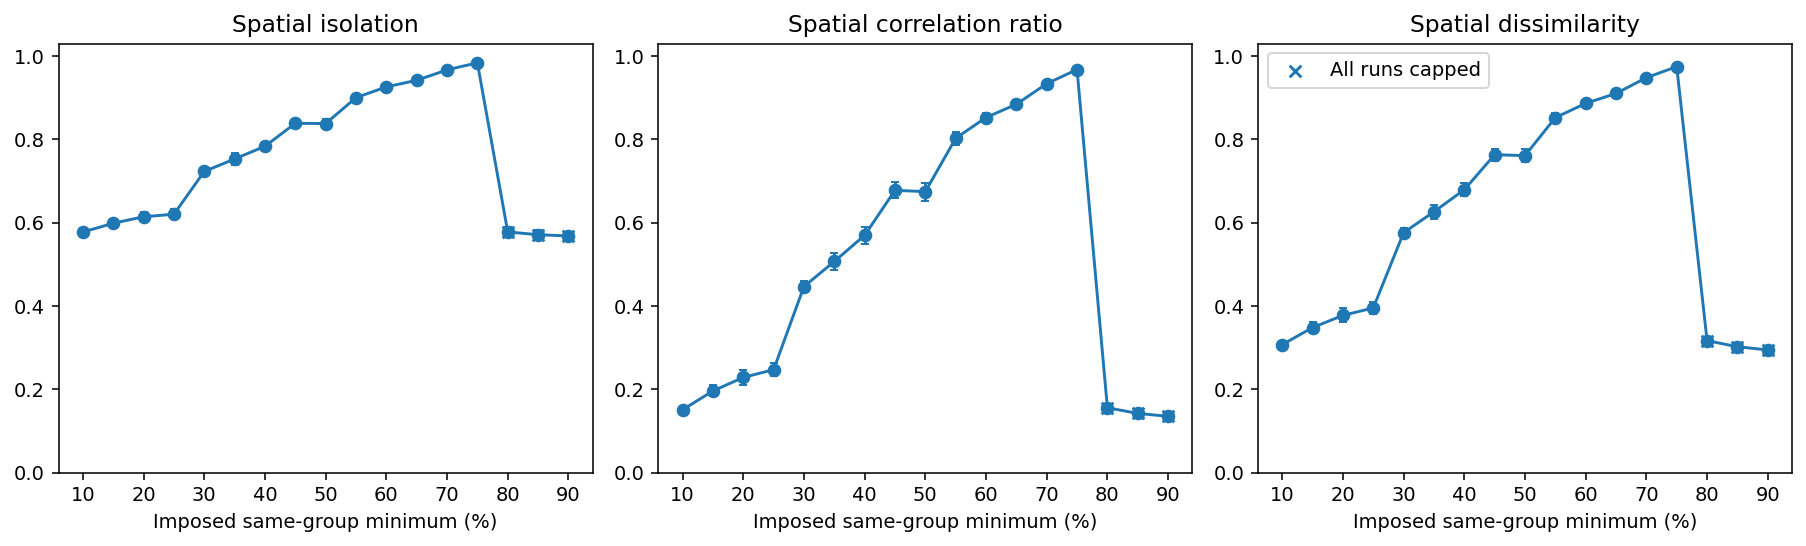

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, mean, sd, title in zip(axes,
        ['isolation_mean', 'ratio_mean', 'dissimilarity_mean'],
        ['isolation_sd', 'ratio_sd', 'dissimilarity_sd'],
        ['Spatial isolation', 'Spatial correlation ratio', 'Spatial dissimilarity']):
    ax.errorbar(summary.index, summary[mean], yerr=summary[sd],
                fmt='o-', capsize=2)
    capped = summary.index[summary.settled_share.eq(0)]
    ax.scatter(capped, summary.loc[capped, mean], marker='x',
               label='All runs capped')
    ax.set(title=title, xlabel='Imposed same-group minimum (%)', ylim=(0, 1.03))
axes[-1].legend()
fig.tight_layout()
plt.show()

## 7. Interpret the policy evidence
The mean spatial correlation ratio rises from **0.151 at 10%** to **0.447 at 30%**, **0.934 at 70%**, and **0.968 at 75%**. All 30 runs settle at each of those settings. The stronger imposed minima produce substantially greater neighborhood separation, despite eventual conformity with the rule.

At **90%**, the mean ratio falls to **0.135**, but all 30 runs reach the cap. A mixed-looking endpoint is therefore not evidence of settled mixing. The indices describe segregation at the specified neighborhood scale; they do not directly describe the size or compactness of territories, residents' well-being, or revolt risk.

The conclusion combines spatial segregation with settling: **meeting the imposed rule does not ensure integration, and low endpoint segregation does not ensure that relocation has resolved.**